In [5]:
import os
print("MONGODB_URI set:", bool(os.environ.get("MONGODB_URI")))

MONGODB_URI set: True


# Job Postings NLP 1: Text Cleaning & Skill Extraction

Takes the scraper's master CSVs and turns each posting's free text into structured features:

| Feature | Columns |
|---|---|
| Clean text (boilerplate removed) | `Clean_Text`, `Resp_Text`, `Qual_Text`, `Word_Count`, `Gov_Skill_Levels` |
| Skills (6 categories, ~120 skills) | `Skills`, `Skills_Software`, `Skills_Business`, `Skills_Healthcare`, `Skills_Trades`, `Skills_Soft`, `Skills_Languages`, `Skill_Count` |
| Certifications / licences | `Certifications` |
| Pre-hire checks & conditions | `Requirements` |
| Education | `Education_Required`, `Education_Rank`, `Education_Preferred`, `Education_Field`, `Equivalency_Accepted` |
| Experience | `Experience_Years_Min`, `Experience_Years_Preferred`, `Experience_Level` |

Extraction is rule-based (a skill taxonomy plus regex patterns), so every result can be traced back to the text that produced it, and it needs no training data. The output feeds the next notebooks (topic modelling, salary prediction, job matching).

**To use:** run all cells. It reads the scraper's newest master CSV (and `past_postings_master.csv`) straight from your Google Drive and saves the results back to the same Drive folder. If your scraper's `OUT_DIR` isn't `MyDrive/Capstone/sk_jobs_data`, set `DATA_DIR` in step 2.

## 1. Setup

In [6]:
import re
import unicodedata
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)


## 2. Load the scraped postings from Google Drive
Reads the scraper's output folder (its `OUT_DIR`): the **newest** `saskatchewan_public_sector_jobs_master_<date>.csv` plus `past_postings_master.csv` if it exists. A posting in both keeps its current row, and `Posting_Status` says which file it came from. Results are saved to an `nlp` subfolder of the same Drive folder. Change `DATA_DIR` if your folder is somewhere else.

In [7]:
import os
import sys
from datetime import date, datetime, timezone
from getpass import getpass

from pymongo import ASCENDING, DESCENDING, MongoClient, ReplaceOne

def get_mongo_uri() -> str:
    """Atlas connection string from the MONGODB_URI environment variable.

    GitHub Actions: set it as a repository secret and pass it in `env:`.
    Local: `export MONGODB_URI="mongodb+srv://..."` (PowerShell: `$env:MONGODB_URI="..."`).
    Interactive run without it set: asks in a hidden prompt, nothing is saved.
    """
    uri = os.environ.get("MONGODB_URI", "").strip()
    if not uri and sys.stdin.isatty() or not uri and "ipykernel" in sys.modules:
        uri = getpass("MongoDB Atlas connection string: ").strip()
    if not uri.startswith("mongodb"):
        raise RuntimeError("Set MONGODB_URI to your Atlas connection string (mongodb+srv://...)")
    return uri

def connect(uri: str) -> MongoClient:
    client = MongoClient(uri, serverSelectionTimeoutMS=20000, tz_aware=True)
    client.admin.command("ping")  # fail fast with a clear error
    return client

In [8]:
# Fields the pipeline adds for its own bookkeeping - not needed for NLP
_PIPELINE_FIELDS = {"content_hash", "created_at", "updated_at"}


def load_postings_from_mongo(db, statuses=("open", "closed"), sources=None) -> pd.DataFrame:
    """Read postings straight from the scraper's `postings` collection.

    Each document already has every master-schema column plus first_seen / last_seen /
    status / closed_date. `status` becomes `Posting_Status` (Open / Closed) like the CSV route.
    """
    query = {"status": {"$in": list(statuses)}}
    if sources:
        query["Source"] = {"$in": list(sources)}
    projection = {f: 0 for f in _PIPELINE_FIELDS}
    docs = list(db["postings"].find(query, projection))
    if not docs:
        raise RuntimeError(f"No postings found in {db.name}.postings for {query}")
    df = pd.DataFrame(docs).drop(columns=["_id"], errors="ignore")
    df["Posting_Status"] = df["status"].str.title()
    df["Source_File"] = f"mongodb:{db.name}.postings"
    df = df.where(df.notna(), None)
    print(f"{db.name}.postings: {len(df):,} postings "
          f"({(df['Posting_Status'] == 'Open').sum():,} open, {(df['Posting_Status'] == 'Closed').sum():,} closed)")
    return df

In [9]:
SOURCE_DB = os.environ.get("MONGODB_DB", "sk_jobs")         # scraper database (same variable the scraper uses)
NLP_DB = os.environ.get("MONGODB_NLP_DB", "sk_jobs_nlp")    # results database (created automatically)
STATUSES = ["open", "closed"]
SOURCES = None               # e.g. ["SGI", "SaskPower"]; None = all employers

client = connect(get_mongo_uri())
postings = load_postings_from_mongo(client[SOURCE_DB], STATUSES, SOURCES)
postings.groupby(["Source", "Posting_Status"]).size().unstack(fill_value=0)

sk_jobs.postings: 2,643 postings (2,225 open, 418 closed)


Posting_Status,Closed,Open
Source,,
Government of Saskatchewan,34,100
SGI,0,4
SaskEnergy,1,5
SaskPower,0,12
SaskTel,0,14
SaskWater,52,0
Saskatchewan Health Authority,331,2088
Saskatchewan Liquor and Gaming Authority,0,2


## 3. Clean the text
- **Normalize:** unicode, quotes, bullets, and remove URLs, emails and phone numbers.
- **Recover sections:** responsibilities, qualifications and other text for every source. SHA writes them inline (`Job Description: … Education … Licenses … Competencies …`), so they're split out here. Where a description repeats the other sections, the repeat is removed.
- **Remove boilerplate:** sentences that repeat across a large share of one employer's postings (benefits blurbs, the Government's standard *Job Capabilities* list, diversity statements). Left in, they would make every posting from that employer look like it wants the same skills. Raise `min_share` to remove less.
- **Government skills framework:** every Government posting lists the same 10 framework skills (Communication, Critical Thinking, ...) with a level from A to E. The levels go into `Gov_Skill_Levels`, and the block is taken out of the text so it doesn't swamp the skill counts.

In [10]:
def normalize_text(text) -> str:
    """Unicode clean-up, bullets -> line breaks, drop URLs/emails/phone numbers."""
    if not isinstance(text, str) or not text.strip():
        return ""
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    text = re.sub(r"[•●▪‣⁃·]|(?<=\s)\*(?=\s)", "\n", text)  # bullets
    text = re.sub(r"(?:https?:)?//\S+|www\.\S+", " ", text)                 # URLs
    text = re.sub(r"\S+@\S+\.\w+", " ", text)                                # emails
    text = re.sub(r"\(?\b\d{3}\)?[-.\s]\d{3}[-.\s]\d{4}\b", " ", text)       # phone numbers
    text = re.sub(r"#LI-\w+", " ", text)
    text = re.sub(r"[ \t]+", " ", text)
    return text.strip()


# SHA writes every section inline: 'Job Description: ... Education ... Licenses ... Competencies ...'
SHA_LABELS = ["Job Description", "Experience", "Education", "Licenses", "Certifications?",
              "Competencies", "Knowledge and Abilities", "Other Information"]
_SHA_SPLIT = re.compile(rf"\b({'|'.join(SHA_LABELS)})\b:?\s", re.I)


def sha_sections(text: str) -> dict:
    """Split an SHA description into its inline sections (header facts are dropped)."""
    start = text.find("Job Description")
    if start < 0:
        return {}
    body = re.sub(r"Human Resources Exemption:\s*\w+", " ", text[start:])
    parts = _SHA_SPLIT.split(body)
    sections = {}
    for label, value in zip(parts[1::2], parts[2::2]):
        sections.setdefault(label.title(), value.strip())
    return sections


def recover_sections(row) -> tuple[str, str, str]:
    """(responsibilities, qualifications, other) text for one posting, whatever the source."""
    desc = normalize_text(row.get("Description"))
    resp = normalize_text(row.get("Responsibilities"))
    qual = normalize_text(row.get("Qualifications"))
    if not resp and not qual and "Job Description" in desc:  # SHA
        s = sha_sections(desc)
        resp = s.get("Job Description", "")
        qual = "\n".join(f"{k}: {s[k]}" for k in ("Experience", "Education", "Licenses", "Certification",
                                                    "Certifications", "Competencies", "Knowledge And Abilities")
                         if s.get(k))
        return resp, qual, s.get("Other Information", "")
    if resp and qual.startswith(resp[:80]):  # qualifications text repeats the duties
        qual = qual.replace(resp, " ").strip()
    # The description often repeats the other two sections - don't count them twice.
    other = desc
    for part in (resp, qual):
        if part and part[:80] in other:
            other = other.replace(part, " ")
    return resp, qual, other.strip()


_SENT_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"(])|\n+")


def sentences(text: str) -> list[str]:
    return [s.strip() for s in _SENT_SPLIT.split(text or "") if s.strip()]


def boilerplate_by_source(df: pd.DataFrame, cols, min_share: float = 0.3, min_posts: int = 3) -> dict:
    """Sentences that repeat across a source's postings (benefits blurbs, the Government's
    standard 'Job Capabilities' list, diversity statements...). A sentence counts as
    boilerplate when it appears in at least max(min_posts, min_share x postings) postings."""
    found = {}
    for source, group in df.groupby("Source"):
        counts = Counter()
        for _, row in group.iterrows():
            counts.update({s.lower() for c in cols for s in sentences(row[c]) if len(s) >= 25})
        cutoff = max(min_posts, min_share * len(group))
        found[source] = {s for s, n in counts.items() if n >= cutoff}
    return found


def strip_boilerplate(text: str, boiler: set) -> str:
    return "\n".join(s for s in sentences(text) if s.lower() not in boiler)


# The Government lists the same 10 framework skills on every posting, only the levels change.
# Keep the levels as their own column and take the block out of the text, so it doesn't
# make every Government posting look like it asks for the same skills.
_GOV_SKILLS = re.compile(r"Job Skills:\s*(.*?)(?:Learn more about[^.\n]*\.?|$)", re.S)
_GOV_LEVEL = re.compile(r"([A-Z][\w ,&]+?)\s*\(Level ([A-E])\)")


def pull_gov_skill_levels(text: str) -> tuple[str, str | None]:
    m = _GOV_SKILLS.search(text or "")
    if not m:
        return text, None
    levels = "; ".join(f"{name.strip()}: {lvl}" for name, lvl in _GOV_LEVEL.findall(m.group(1)))
    return (text[:m.start()] + text[m.end():]).strip(), levels or None


def clean_postings(df: pd.DataFrame, min_share: float = 0.3) -> pd.DataFrame:
    out = df.copy()
    secs = out.apply(recover_sections, axis=1, result_type="expand")
    out[["Resp_Text", "Qual_Text", "Other_Text"]] = secs
    pulled = out["Qual_Text"].apply(pull_gov_skill_levels)
    out["Qual_Text"] = pulled.str[0]
    out["Gov_Skill_Levels"] = pulled.str[1]
    boiler = boilerplate_by_source(out, ["Resp_Text", "Qual_Text", "Other_Text"], min_share)
    for col in ("Resp_Text", "Qual_Text", "Other_Text"):
        out[col] = [strip_boilerplate(t, boiler[s]) for t, s in zip(out[col], out["Source"])]
    out["Clean_Text"] = (out["Job_Title"].fillna("") + ".\n" + out["Resp_Text"] + "\n"
                         + out["Qual_Text"] + "\n" + out["Other_Text"]).str.strip()
    out["Word_Count"] = out["Clean_Text"].str.split().str.len()
    removed = {s: len(b) for s, b in boiler.items()}
    print("Boilerplate sentences removed per source:", removed)
    return out


In [11]:
clean = clean_postings(postings, min_share=0.3)
clean.groupby("Source")["Word_Count"].describe()[["count", "25%", "50%", "75%"]].round(0)


Boilerplate sentences removed per source: {'Government of Saskatchewan': 7, 'SGI': 6, 'SaskEnergy': 18, 'SaskPower': 18, 'SaskTel': 5, 'SaskWater': 7, 'Saskatchewan Health Authority': 0, 'Saskatchewan Liquor and Gaming Authority': 0}


,count,25%,50%,75%
Source,,,,
Government of Saskatchewan,134.0,379.0,484.0,563.0
SGI,4.0,802.0,900.0,934.0
SaskEnergy,6.0,326.0,356.0,384.0
SaskPower,12.0,228.0,326.0,422.0
SaskTel,14.0,473.0,573.0,776.0
SaskWater,52.0,350.0,476.0,570.0
Saskatchewan Health Authority,2419.0,78.0,104.0,157.0
Saskatchewan Liquor and Gaming Authority,2.0,954.0,960.0,967.0


In [12]:
# Look at one cleaned posting
example = clean.sample(1, random_state=7).iloc[0]
print(example["Source"], "|", example["Job_Title"])
print("\nRESPONSIBILITIES:\n", example["Resp_Text"][:800])
print("\nQUALIFICATIONS:\n", example["Qual_Text"][:800])


Saskatchewan Health Authority | Licensed Practical Nurse

RESPONSIBILITIES:
 Promotes health and healing and provides

QUALIFICATIONS:
 Education: as a member of the health care team to achieve optimum care for clients/patients/residents in all phases of health care.
Licenses: Licensed Practical Nurse (LPN)
Competencies: Leadership skills Interpersonal skills Basic - Computer skills Communication skills Organizational skills
Knowledge And Abilities: Ability to work as a member of a multi-disciplinary team Ability to work independently


## 4. Skill taxonomy
Each skill is a regex. Edit, add or remove entries here and everything below picks them up. Certifications and pre-hire requirements are kept in separate lists.

In [13]:
# Skill taxonomy: category -> {canonical skill: regex}. Patterns are case-insensitive;
# wrap a part in (?-i:...) to make it case-sensitive (e.g. 'Excel' vs 'excel at').
# Add or edit entries here - everything downstream picks them up.
SKILL_TAXONOMY = {
    "Software & Data": {
        "Microsoft Office": r"\b(?:ms|microsoft) office\b|\bOffice 365\b|\bM365\b",
        "Excel": r"(?-i:\bExcel\b)|\bspreadsheets?\b",
        "Word": r"(?-i:\b(?:MS |Microsoft )Word\b)|\bword processing\b",
        "Outlook": r"(?-i:\bOutlook\b)",
        "PowerPoint": r"\bpower ?point\b",
        "SharePoint": r"\bshare ?point\b",
        "SQL": r"\bsql\b|\bt-sql\b",
        "Python": r"\bpython\b",
        "R": r"(?-i:\bR\b)(?= programming| language|,| or | and |/)",
        "Java": r"\bjava\b(?!\s*script)",
        "JavaScript": r"\bjavascript\b|\btypescript\b",
        "C# / .NET": r"\bc#|\.net\b",
        "Power BI": r"\bpower ?bi\b",
        "Tableau": r"\btableau\b",
        "SAP": r"(?-i:\bSAP\b)",
        "Salesforce": r"\bsalesforce\b",
        "GIS / ArcGIS": r"\bgis\b|\barcgis\b|\bqgis\b|geographic information system",
        "AutoCAD / CAD": r"\bautocad\b|\bcad (?:drafting|software|design|drawings?|technician)\b|\bcomputer[- ]aided (?:design|drafting)\b",  # not 'CAD' the currency
        "SCADA": r"\bscada\b",
        "Cloud (Azure/AWS)": r"\bazure\b|\baws\b|amazon web services|\bcloud (?:platform|computing|services|infrastructure)\b",
        "Networking": r"\bnetwork(?:ing)? (?:infrastructure|administration|protocols|security)\b|\btcp/ip\b|\blan/wan\b|\brouting and switching\b",
        "Cybersecurity": r"\bcyber ?security\b|\binformation security\b|\bsecurity operations\b",
        "Linux / Unix": r"\blinux\b|\bunix\b",
        "Database management": r"\bdatabases?\b",
        "Data analysis": r"\bdata analy(?:sis|tics|ze|zing)\b|\banalytics\b|\bstatistical analysis\b",
        "Machine learning / AI": r"\bmachine learning\b|\bartificial intelligence\b|\b(?-i:AI)\b|\bdata scien(?:ce|tist)\b",
        "ERP systems": r"\berp\b|\benterprise resource planning\b|\bworkday\b|\boracle (?:cloud|ebs|fusion)\b",
        "Electronic health records": r"\belectronic (?:health|medical|patient) records?\b|\bemr\b|\behr\b|\bcerner\b|\bmeditech\b",
        "Computer skills": r"\bcomputer (?:skills|literacy|literate|applications|proficiency)\b",
    },
    "Business & Management": {
        "Project management": r"\bproject management\b|\bmanag(?:e|ing) (?:multiple )?projects\b",
        "Budgeting": r"\bbudget(?:s|ing|ary)?\b",
        "Accounting": r"\baccounting\b|\baccounts (?:payable|receivable)\b|\bbookkeeping\b",
        "Financial analysis": r"\bfinancial (?:analysis|reporting|statements|modelling|modeling)\b",
        "Forecasting": r"\bforecast(?:s|ing)?\b",
        "Procurement": r"\bprocurement\b|\bpurchasing\b|\btender(?:s|ing)\b",
        "Contract management": r"\bcontract (?:management|administration|negotiation)\b|\bmanag(?:e|ing) contracts\b",
        "Policy & legislation": r"\bpolicy (?:development|analysis|research)\b|\bpolicies and procedures\b|\blegislation\b",
        "Business analysis": r"\bbusiness (?:analysis|requirements|process(?:es)?)\b",
        "Risk management": r"\brisk (?:management|assessments?|analysis)\b",
        "Change management": r"\bchange management\b|\bmanag(?:e|ing) change\b",
        "Stakeholder engagement": r"\bstakeholders?\b",
        "Strategic planning": r"\bstrategic (?:planning|plans?|direction|thinking)\b",
        "Report writing": r"\breport writing\b|\b(?:prepare|write|writing|preparing) (?:\w+ ){0,2}reports\b",
        "Research": r"\bresearch\b",
        "Auditing": r"\baudit(?:s|ing)?\b",
        "Supervision": r"\bsupervis(?:e|es|ing|ion|ory)\b",
        "Sales": r"\bsales\b",
        "Customer service": r"\bcustomer service\b|\bclient service\b|\bcustomer experience\b",
        "Scheduling": r"\bscheduling\b|\bschedul(?:e|es) (?:appointments|staff|shifts)\b",
        "Records management": r"\brecords? management\b|\bfiling\b|\brecord[- ]keeping\b",
        "Training & facilitation": r"\bfacilitat(?:e|ion|ing)\b|\b(?:deliver|provide|conduct)(?:s|ing)? training\b",
        "Case management": r"\bcase management\b|\bcaseload\b",
        "Human resources": r"\bhuman resources\b(?! exemption)|\blabour relations\b|\brecruitment and (?:selection|retention strategies)\b|\btalent acquisition\b",
    },
    "Healthcare": {
        "Patient care": r"\bpatient care\b|\bclient care\b|\bresident care\b|\bpersonal care\b",
        "Patient assessment": r"\b(?:patient|client|health|nursing|clinical) assessments?\b",
        "Medication administration": r"\bmedications?\b",
        "Infection prevention & control": r"\binfection (?:prevention|control)\b|\bipac\b",
        "Clinical documentation": r"\b(?:clinical|nursing|patient|client|health|medical) (?:documentation|records|charts?)\b|\bcharting\b",
        "Mental health & addictions": r"\bmental health\b|\baddictions?\b|\bpsychiatr(?:y|ic)\b",
        "Acute care": r"\bacute care\b",
        "Long-term care": r"\blong[- ]term care\b|\bcontinuing care\b",
        "Home care": r"\bhome care\b",
        "Emergency care": r"\bemergency (?:department|care|medicine|nursing)\b",
        "Critical care": r"\bcritical care\b|\bintensive care\b|\bicu\b",
        "Palliative care": r"\bpalliative\b|\bend[- ]of[- ]life\b",
        "Maternal & pediatric care": r"\bpediatric\b|\bpaediatric\b|\bobstetric\b|\bmaternal\b|\bneonatal\b|\blabour and delivery\b",
        "Wound care": r"\bwound care\b",
        "Phlebotomy": r"\bphlebotomy\b|\bvenipuncture\b|\bspecimen collection\b",
        "Laboratory testing": r"\blaboratory\b|\blab testing\b",
        "Diagnostic imaging": r"\bdiagnostic imaging\b|\bx-ray\b|\bradiograph|\bultrasound\b|\bmri\b|\bct scan|\bmammograph",
        "Pharmacy": r"\bpharmac(?:y|ist|eutical)\b|\bdispens(?:e|ing)\b",
        "Rehabilitation": r"\brehabilitation\b|\bphysiotherap|\boccupational therap|\bspeech[- ]language\b",
        "Crisis intervention": r"\bcrisis intervention\b|\bde-?escalation\b|\bnon-?violent crisis\b",
        "Dementia care": r"\bdementia\b|\bgentle persuasive approach\b",
        "Food services": r"\bfood (?:services|preparation|handling)\b|\bnutrition\b|\bdietary\b",
        "Sterile processing": r"\breprocessing\b|\bsteriliz|\bsterile processing\b",
    },
    "Trades & Technical": {
        "Electrical": r"\belectrical\b",
        "Mechanical": r"\bmechanical\b",
        "Instrumentation & control": r"\binstrumentation\b|\bplc\b|\bprogrammable logic\b",
        "Plumbing & gas fitting": r"\bplumb(?:ing|er)\b|\bgas ?fitt",
        "HVAC & refrigeration": r"\bhvac\b|\brefrigeration\b|\bheating,? ventilation\b",
        "Welding": r"\bweld(?:ing|er)\b",
        "Carpentry": r"\bcarpent(?:ry|er)\b",
        "Maintenance & repair": r"\bmaintenance\b|\brepairs?\b",
        "Construction": r"\bconstruction\b",
        "Heavy equipment operation": r"\bheavy equipment\b|\bequipment operat",
        "Water & wastewater treatment": r"\bwater (?:treatment|distribution)\b|\bwastewater\b",
        "Surveying": r"\bsurvey(?:ing|or)\b",
        "Engineering design": r"\bengineering design\b|\bdesign (?:drawings|specifications)\b",
        "Tools & equipment": r"\btools and equipment\b|\bhand and power tools\b",
        "Boiler operation": r"\bboiler\b",
        "Safety / OH&S": r"\boccupational health and safety\b|\bohs\b|\bsafety (?:programs?|procedures|standards|regulations)\b",
        "Telecommunications": r"\btelecommunications?\b|\bfibre\b|\bfiber optic\b|\bwireless\b",
        "Driving / vehicle operation": r"\bdriving\b|\boperat(?:e|ing) (?:a )?(?:vehicle|truck)s?\b",
    },
    "Soft skills": {
        "Communication": r"\bcommunicat(?:ion|e|ing)\b",
        "Teamwork & collaboration": r"\bteam ?work\b|\bcollaborat(?:e|ion|ive|ively)\b|\bteam player\b",
        "Leadership": r"\bleadership\b|\blead (?:a |the )?team\b",
        "Problem solving": r"\bproblem[- ]solving\b|\bsolve problems\b",
        "Critical thinking": r"\bcritical thinking\b|\banalytical (?:skills|thinking|abilities)\b",
        "Organization & time management": r"\borganizational skills\b|\btime management\b|\bprioriti[sz]",
        "Interpersonal skills": r"\binterpersonal\b",
        "Attention to detail": r"\battention to detail\b|\bdetail[- ]oriented\b|\baccuracy\b",
        "Decision making": r"\bdecision[- ]making\b|\bjudg(?:e)?ment\b",
        "Adaptability": r"\badaptab|\bflexib(?:le|ility)\b",
        "Independent work": r"\bwork independently\b|\bself[- ](?:directed|motivated|starter)\b",
        "Conflict resolution": r"\bconflict (?:resolution|management)\b|\bresolv(?:e|ing) conflicts?\b",
        "Negotiation": r"\bnegotiat",
        "Coaching & mentoring": r"\bcoach(?:ing)?\b|\bmentor(?:ing|ship)?\b",
        "Cultural competency": r"\bcultural(?:ly)? (?:competen|safe|aware|respons|sensitiv)|\bindigenous\b|\bfirst nations\b",
        "Written communication": r"\bwritten communication\b|\bwriting skills\b",
        "Presentation skills": r"\bpresentation(?:s| skills)\b|\bpublic speaking\b",
    },
    "Languages": {
        "French": r"\bfrench\b|\bbilingual\b",
        "Cree": r"\bcree\b",
        "Dene": r"\bdene\b",
        "Michif": r"\bmichif\b",
    },
}

# Certifications / licences - extracted separately from skills.
CERTIFICATIONS = {
    "Driver's licence": r"\bdriver'?s'? licen[cs]e\b|\bclass [1-5][a-z]?\b",
    "Registered Nurse (RN)": r"\bregistered nurse\b|\b(?-i:RN)\b|\bCRNS\b|\bSRNA\b",
    "Licensed Practical Nurse (LPN)": r"\blicensed practical nurse\b|\b(?-i:LPN)\b|\bSALPN\b",
    "Registered Psychiatric Nurse (RPN)": r"\bregistered psychiatric nurse\b|\b(?-i:RPN)\b",
    "Continuing Care Assistant (CCA)": r"\bcontinuing care assistant\b|\b(?-i:CCA)\b",
    "Professional Engineer (P.Eng./EIT)": r"\bp\.?\s?eng\b|\bprofessional engineer|\bengineer[- ]in[- ]training\b|\b(?-i:EIT)\b|\bAPEGS\b",
    "Technologist (A.Sc.T./C.Tech)": r"\ba\.?sc\.?t\b|\bc\.?tech\b|\bSASTT\b|\bapplied science technologist\b",
    "CPA": r"\b(?-i:CPA)\b|\bchartered professional accountant\b",
    "PMP": r"\b(?-i:PMP)\b|\bproject management professional\b",
    "ITIL": r"\bitil\b",
    "Journeyperson / Red Seal": r"\bjourney(?:person|man|ed)\b|\bred seal\b",
    "Electrician licence": r"\belectrician\b",
    "Gas fitter licence": r"\bgas ?fitter\b",
    "Boiler / power engineer": r"\bpower engineer\b|\bfireman\b|\bboiler operator\b",
    "Water/wastewater operator cert.": r"\boperator certification\b|\bwater (?:treatment|distribution) (?:class|level|operator)\b",
    "Pesticide applicator": r"\bpesticide applicator\b",
    "BLS / CPR": r"\b(?-i:BLS)\b|\bbasic life support\b|\bcpr\b",
    "First Aid": r"\bfirst aid\b",
    "ACLS / PALS / NRP": r"\b(?-i:ACLS|PALS|NRP|TNCC|ENPC)\b",
    "Non-Violent Crisis Intervention": r"\bnon-?violent crisis\b|\b(?-i:NVCI)\b",
    "TLR (Transferring, Lifting, Repositioning)": r"\b(?-i:TLR)\b|\btransferring,? lifting\b",
    "WHMIS": r"\bwhmis\b",
    "Food Safe": r"\bfood ?safe\b|\bfood handler",
    "Medical Laboratory Technologist (MLT)": r"\b(?-i:MLT|CSMLS)\b|\bmedical laboratory technologist\b",
    "Medical Radiation Technologist": r"\b(?-i:MRT|CAMRT)\b|\bmedical radiation technologist\b",
    "Social Worker registration": r"\b(?-i:SASW|RSW)\b|\bregistered social worker\b",
    "Security certs (CISSP etc.)": r"\b(?-i:CISSP|CISM|CISA|Security\+|CEH)\b",
}
# Pre-hire checks / conditions
REQUIREMENTS = {
    "Criminal record check": r"\bcriminal record\b|\bcriminal background\b",
    "Vulnerable sector check": r"\bvulnerable sector\b",
    "Drug & alcohol test": r"\bdrug and alcohol\b|\bsafety[- ]sensitive\b",
    "Security clearance": r"\bsecurity clearance\b|\bpersonnel risk assessment\b",
    "Physical demands": r"\bphysical(?:ly)? (?:demands|requirements|fit|demanding)\b|\blift(?:ing)? (?:up to )?\d+\s*(?:lb|kg|pounds)",
    "Travel required": r"\btravel required:\s*yes\b|\btravel (?:is )?required\b(?!:)|\brequired to travel\b|\bovernight\b",
    "Shift / on-call work": r"\bshift work\b|\bon[- ]call\b|\bevenings?(?:,| and) weekends\b|\brotating shifts?\b|\bshift information:[^:]{0,40}\bnights?\b",
}


def compile_patterns(mapping: dict) -> dict:
    return {name: re.compile(pattern, re.I) for name, pattern in mapping.items()}


SKILL_PATTERNS = {cat: compile_patterns(skills) for cat, skills in SKILL_TAXONOMY.items()}
SKILL_CATEGORY = {skill: cat for cat, skills in SKILL_TAXONOMY.items() for skill in skills}
CERT_PATTERNS = compile_patterns(CERTIFICATIONS)
REQ_PATTERNS = compile_patterns(REQUIREMENTS)


## 5. Extractors
- **Skills / certifications / requirements:** a pattern match anywhere in the cleaned text.
- **Education:** read from the qualifications text only. Within a sentence, levels joined by "or" are alternatives, so the *lowest* counts ("diploma or degree" → Diploma). Otherwise the *highest* counts ("Grade 12 and a CCA certificate" → Certificate), and the same goes across sentences. Clauses that say "asset" or "preferred" go to `Education_Preferred` instead.
- **Experience:** `Experience_Years_Min` is the largest minimum stated outside "asset" sentences. "No previous experience" or "new graduates" counts as 0.
- **Experience level:** from title keywords (Director, Manager, Senior, Student...) and otherwise from years.

In [14]:
def find_all(text: str, patterns: dict) -> list[str]:
    return [name for name, rx in patterns.items() if rx.search(text)]


def extract_skills(text: str) -> dict:
    """{'Skills': [...all...], 'Skills_<Category>': [...]} for one posting."""
    out, every = {}, []
    for cat, patterns in SKILL_PATTERNS.items():
        found = find_all(text, patterns)
        out[f"Skills_{cat.split(' ')[0].replace('&', '')}"] = found
        every += found
    out["Skills"] = every
    return out


_PREFERRED = re.compile(r"\basset\b|\bprefer(?:red|ence|ably)\b|\badvantage\b|\bnice to have\b|\bconsidered\b|\bdesirable\b", re.I)

EDUCATION_LEVELS = [  # (rank, label, regex) - checked on qualification text only
    (6, "Doctorate", r"\bph\.?\s?d\b|\bdoctor(?:ate|al)\b|\bdoctor of\b|\b(?-i:MD)\b"),
    (5, "Master's", r"\bmaster'?s?\b|\b(?:advanced|graduate|post-?graduate) degree\b|\b(?-i:MBA|MSW|MSc|M\.Sc|MPA|MPH)\b"),
    (4, "Bachelor's", r"\bbachelor'?s?\b|\bbaccalaureate\b|\buniversity degree\b|\bdegree\b(?!\s+of\b)|\b(?-i:BSc|B\.Sc|BSN|BA|B\.A\.|BEd|BComm|B\.Comm)\b"),
    (3, "Diploma", r"(?<!grade 12 )(?<!high school )(?<!secondary )\bdiploma\b"),
    (2, "Certificate / Trade", r"\bjourney(?:person|man)\b|\bred seal\b|\bapprentice|\bcertificate\b"),
    (1, "High school", r"\bgrade (?:12|twelve|xii)\b|\bhigh school\b|\bsecondary school\b|\b(?-i:GED|ABE)\b"),
]
EDU_RX = [(rank, label, re.compile(rx, re.I)) for rank, label, rx in EDUCATION_LEVELS]
# Certificates that are not education (removed before matching levels)
_NOT_EDUCATION = re.compile(
    r"\b(?:first aid|cpr|bls|basic life support|driver'?s?|food ?safe|food handler|whmis|police|criminal record"
    r"|vulnerable sector|security clearance|tlr|nvci|non-?violent crisis)\b[^.\n]{0,40}?\bcertific\w*", re.I)
_PARENS = re.compile(r"\([^)]*\)")
_FIELD = re.compile(
    r"\b(?i:degree|diploma|certificate|bachelor(?:'s)?|master(?:'s)?|doctorate)\s+(?i:degree\s+)?(?:of|in)\s+"
    r"((?:[A-Z][\w&'/-]*|and|of|or|the|in|[ \t]|,)+?)"
    r"(?=[ \t]*(?:[.;:(\n]|,? or\b|\b(?:from|plus|with)\b|$)|[ \t]+(?!(?:and|of|or|the|in)\b)[a-z])")
# 'Continuing Care Assistant certificate', 'Biomedical Engineering Technology diploma'
_FIELD_BEFORE = re.compile(r"((?:\b[A-Z][\w&'/-]+[ \t]){1,6})(?i:certificate|diploma|degree)\b")


def clean_field(text: str):
    text = squash_ws(text).strip(" ,")
    text = re.sub(r"^(?:Education|Bachelor'?s?|Master'?s?|University|College|Valid|Current|A|An)\s+", "", text)
    text = re.sub(r"^(?:Applied )?(?:Science|Arts|Commerce|Education)\s+in\s+", "", text)  # 'Science in Nursing' -> 'Nursing
    if len(text) < 3 or re.fullmatch(r"(?:Grade 12|High School|Secondary School|Post-?Secondary|University|Related|Applied|Master'?s|Bachelor'?s)?", text, re.I):
        return None
    return text


_CLAUSE = re.compile(r";|,\s*(?=with\b|preferably\b|ideally\b)|(?=\bwith a preference\b)|(?=\bpreference (?:for|given)\b)", re.I)


def education_sentences(text: str) -> list[str]:
    """Sentences, with an 'OR ...' sentence joined to the one before (it's an alternative)."""
    merged = []
    for sent in sentences(text):
        if merged and re.match(r"or\b", sent, re.I):
            merged[-1] += " " + sent
        else:
            merged.append(sent)
    return merged


def extract_education(qual_text: str) -> dict:
    """Required education = across sentences take the highest level; within one sentence
    the lowest (alternatives like 'diploma or degree'). Levels in sentences that say
    'asset' / 'preferred' are reported separately."""
    required, preferred = [], []
    for sent in education_sentences(qual_text):
        sent = _NOT_EDUCATION.sub(" ", sent)
        req_ranks, pref_ranks = [], []
        for clause in _CLAUSE.split(_PARENS.sub("", sent)):
            ranks = [(rank, label) for rank, label, rx in EDU_RX if rx.search(clause)]
            (pref_ranks if _PREFERRED.search(clause) else req_ranks).extend(ranks)
        if req_ranks:  # 'diploma OR degree' -> the lowest; 'Grade 12 AND a certificate' -> the highest
            required.append(min(req_ranks) if re.search(r"\bor\b", sent, re.I) else max(req_ranks))
        if pref_ranks:
            preferred.append(max(pref_ranks))
    req = max(required) if required else None
    edu_text = _NOT_EDUCATION.sub(" ", qual_text or "")
    field = _FIELD.search(edu_text) or _FIELD_BEFORE.search(edu_text)
    return {
        "Education_Required": req[1] if req else None,
        "Education_Rank": req[0] if req else None,
        "Education_Preferred": max(preferred)[1] if preferred else None,
        "Education_Field": clean_field(field.group(1)) if field else None,
        "Equivalency_Accepted": bool(re.search(r"\bequivalen(?:t|cy)\b|\bcombination of (?:education|training)", qual_text or "", re.I)),
    }


_NUM_WORDS = {w: i for i, w in enumerate("zero one two three four five six seven eight nine ten eleven twelve".split())}
_NUM = r"(\d{1,2}(?:\.\d)?|" + "|".join(_NUM_WORDS) + r")"
_YEARS = re.compile(
    rf"\b{_NUM}(?:\s*\(\d{{1,2}}\))?\s*(?:\+|plus)?\s*(?:(?:-|to|\u2013|or)\s*{_NUM}(?:\s*\(\d{{1,2}}\))?\s*(?:\+|plus)?\s*)?"
    rf"(years?|yrs?|months?)'?(?=[^.]{{0,90}}\bexperience)", re.I)
_SHA_EXPERIENCE = re.compile(rf"^Experience:\s*(?:minimum(?: of)?\s*)?{_NUM}\s*(years?|months?)", re.I | re.M)
_WORD_PLUS_DIGITS = re.compile(r"\b(?:[a-z]+-)?[a-z]+\s*\((\d{1,2})\)", re.I)   # 'Twenty-four (24)' -> '24'
_NO_EXPERIENCE = re.compile(r"\bno (?:previous |prior )?experience\b|\bexperience:\s*no previous\b"
                            r"|\bnew graduates?\b|\bentry[- ]level\b", re.I)


def _to_number(token: str) -> float:
    token = token.lower()
    return float(_NUM_WORDS[token]) if token in _NUM_WORDS else float(token)


def extract_experience(qual_text: str, full_text: str) -> dict:
    """Minimum years of experience asked for. Uses the largest lower bound found in
    non-'asset' sentences (e.g. '5 years overall, 2 supervising' -> 5)."""
    required, preferred = [], []
    qual_text = _WORD_PLUS_DIGITS.sub(r"\1", qual_text or "")
    full_text = _WORD_PLUS_DIGITS.sub(r"\1", full_text or "")
    clauses = [c for sent in (sentences(qual_text) or sentences(full_text)) for c in _CLAUSE.split(sent)]
    for sent in clauses:
        hits = list(_YEARS.finditer(sent)) + list(_SHA_EXPERIENCE.finditer(sent))
        for m in hits:
            years = _to_number(m.group(1))
            if m.group(m.lastindex).lower().startswith("month"):
                years = round(years / 12, 1)
            if 0 < years <= 30:
                (preferred if _PREFERRED.search(_PARENS.sub("", sent)) else required).append(years)
    if not required and _NO_EXPERIENCE.search(qual_text + "\n" + full_text):
        required = [0.0]
    return {
        "Experience_Years_Min": max(required) if required else None,
        "Experience_Years_Preferred": max(preferred) if preferred else None,
    }


def experience_level(title: str, years) -> str:
    title = (title or "").lower()
    if re.search(r"\b(?:director|vice[- ]president|chief|executive|deputy minister|assistant deputy)\b", title):
        return "Executive / Director"
    if re.search(r"\b(?:manager|supervisor|superintendent|team lead|head)\b", title):
        return "Manager / Supervisor"
    if re.search(r"\b(?:student|co-?op|intern|summer|apprentice|trainee|in[- ]training)\b", title):
        return "Student / Trainee"
    if re.search(r"\b(?:senior|sr\.?|principal|lead)\b", title):
        return "Senior (by title)"
    if years is None or pd.isna(years):
        return "Not stated"
    return "Entry (0-1 yrs)" if years <= 1 else "Intermediate (2-4 yrs)" if years < 5 else "Senior (5+ yrs)"


def squash_ws(text: str) -> str:
    return re.sub(r"\s+", " ", text or "").strip()


def extract_all(df: pd.DataFrame) -> pd.DataFrame:
    """Run every extractor over the cleaned postings and add the results as columns."""
    rows = []
    for _, r in df.iterrows():
        text, qual = r["Clean_Text"], r["Qual_Text"] or r["Clean_Text"]
        rec = extract_skills(text)
        rec["Certifications"] = find_all(text, CERT_PATTERNS)
        rec["Requirements"] = find_all(text + "\n" + str(r.get("Description") or ""), REQ_PATTERNS)
        rec.update(extract_education(qual))
        rec.update(extract_experience(qual, text))
        rec["Experience_Level"] = experience_level(r["Job_Title"], rec["Experience_Years_Min"])
        rows.append(rec)
    feats = pd.DataFrame(rows, index=df.index)
    feats["Skill_Count"] = feats["Skills"].str.len()
    return pd.concat([df, feats], axis=1)


def skills_long(df: pd.DataFrame) -> pd.DataFrame:
    """One row per (posting, skill) - handy for counts, pivots and charts."""
    long = df[["Record_ID", "Source", "Job_Title", "Posting_Status", "Skills"]].explode("Skills").dropna(subset=["Skills"])
    long = long.rename(columns={"Skills": "Skill"})
    long["Skill_Category"] = long["Skill"].map(SKILL_CATEGORY)
    return long.reset_index(drop=True)


## 6. Run extraction

In [15]:
features = extract_all(clean)
skills_by_posting = skills_long(features)

coverage = features.groupby("Source").agg(
    Postings=("Record_ID", "count"),
    Avg_Skills=("Skill_Count", "mean"),
    Education_Found=("Education_Required", lambda s: s.notna().mean() * 100),
    Experience_Found=("Experience_Years_Min", lambda s: s.notna().mean() * 100),
    Any_Certification=("Certifications", lambda s: s.str.len().gt(0).mean() * 100),
).round(1)
coverage  # % of postings where each feature was found


,Postings,Avg_Skills,Education_Found,Experience_Found,Any_Certification
Source,,,,,
Government of Saskatchewan,134,10.4,45.5,2.2,52.2
SGI,4,9.5,100.0,100.0,25.0
SaskEnergy,6,4.3,100.0,66.7,83.3
SaskPower,12,6.2,66.7,16.7,75.0
SaskTel,14,11.1,50.0,64.3,35.7
SaskWater,52,8.0,61.5,53.8,94.2
Saskatchewan Health Authority,2419,5.5,80.4,17.7,87.8
Saskatchewan Liquor and Gaming Authority,2,12.0,50.0,50.0,0.0


## 7. Explore
SHA makes up ~90% of postings, so the overall charts lean towards healthcare. The per-source table shows each employer separately.

In [16]:
BAR_COLOR, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e6e5e0"


def barh(values: pd.Series, title: str, xlabel: str, pct: bool = False):
    """Simple horizontal bar chart, largest at the top, value printed at each bar end."""
    values = values.sort_values()
    fig, ax = plt.subplots(figsize=(9, 0.32 * len(values) + 1.2))
    ax.barh(values.index, values.values, color=BAR_COLOR, height=0.6)
    for y, v in enumerate(values.values):
        ax.text(v, y, f" {v:.0f}%" if pct else f" {v:,.0f}", va="center", fontsize=9, color=MUTED)
    ax.set_title(title, loc="left", fontsize=12, color=INK, pad=10)
    ax.set_xlabel(xlabel, color=MUTED)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.margins(x=0.12)
    plt.tight_layout()
    plt.show()


def share_of_postings(df: pd.DataFrame, list_col: str, top: int = 20) -> pd.Series:
    """% of postings that mention each item of a list column."""
    counts = df[list_col].explode().value_counts()
    return (counts / len(df) * 100).head(top)


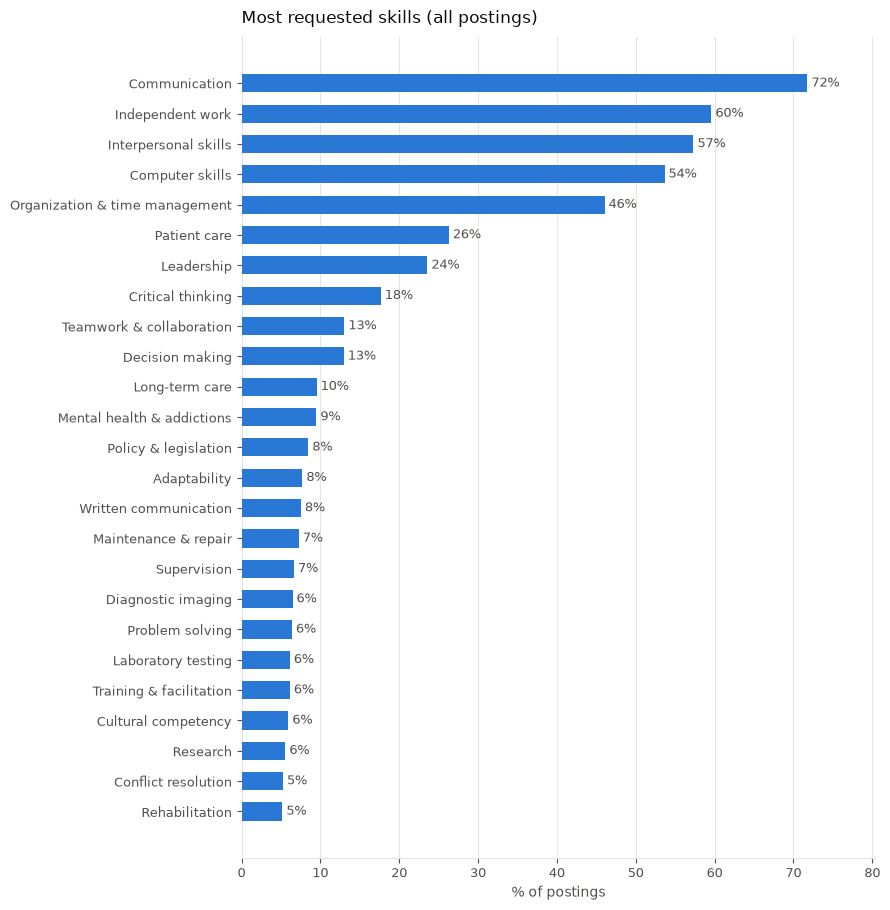

In [17]:
barh(share_of_postings(features, "Skills", 25), "Most requested skills (all postings)", "% of postings", pct=True)


In [18]:
# Top skills per employer (% of that employer's postings)
top_by_source = {}
for source, group in features.groupby("Source"):
    share = share_of_postings(group, "Skills", 10).round(0).astype(int)
    top_by_source[source] = [f"{skill} ({pct}%)" for skill, pct in share.items()]
pd.DataFrame(dict([(k, pd.Series(v)) for k, v in top_by_source.items()])).fillna("")


,Government of Saskatchewan,SGI,SaskEnergy,SaskPower,SaskTel,SaskWater,Saskatchewan Health Authority,Saskatchewan Liquor and Gaming Authority
0,Teamwork & collaboration (69%),Policy & legislation (100%),Maintenance & repair (67%),Electrical (67%),Communication (93%),Maintenance & repair (71%),Communication (74%),Customer service (100%)
1,Adaptability (62%),Leadership (100%),Construction (50%),Maintenance & repair (58%),Decision making (64%),Water & wastewater treatment (67%),Independent work (63%),Communication (100%)
2,Communication (49%),Coaching & mentoring (100%),Budgeting (33%),Construction (42%),Sales (57%),Project management (35%),Interpersonal skills (61%),Teamwork & collaboration (100%)
3,Policy & legislation (49%),Customer service (75%),Plumbing & gas fitting (33%),Supervision (33%),Customer service (57%),Construction (35%),Computer skills (58%),Attention to detail (100%)
4,Stakeholder engagement (46%),Cultural competency (75%),Project management (17%),Project management (25%),Problem solving (57%),Budgeting (29%),Organization & time management (48%),Adaptability (100%)
5,Organization & time management (41%),Presentation skills (75%),Stakeholder engagement (17%),Research (25%),Written communication (50%),Leadership (27%),Patient care (29%),Independent work (100%)
6,Leadership (39%),Stakeholder engagement (50%),Teamwork & collaboration (17%),Training & facilitation (25%),Independent work (43%),Laboratory testing (27%),Leadership (23%),Cultural competency (100%)
7,Cultural competency (34%),Adaptability (50%),Leadership (17%),Teamwork & collaboration (25%),Interpersonal skills (36%),Communication (25%),Critical thinking (19%),Mechanical (50%)
8,Supervision (31%),Negotiation (50%),Presentation skills (17%),Problem solving (25%),Attention to detail (36%),Teamwork & collaboration (25%),Decision making (12%),Maintenance & repair (50%)
9,Decision making (31%),Rehabilitation (25%),Computer skills (17%),Decision making (25%),Business analysis (36%),Database management (25%),Long-term care (10%),Microsoft Office (50%)


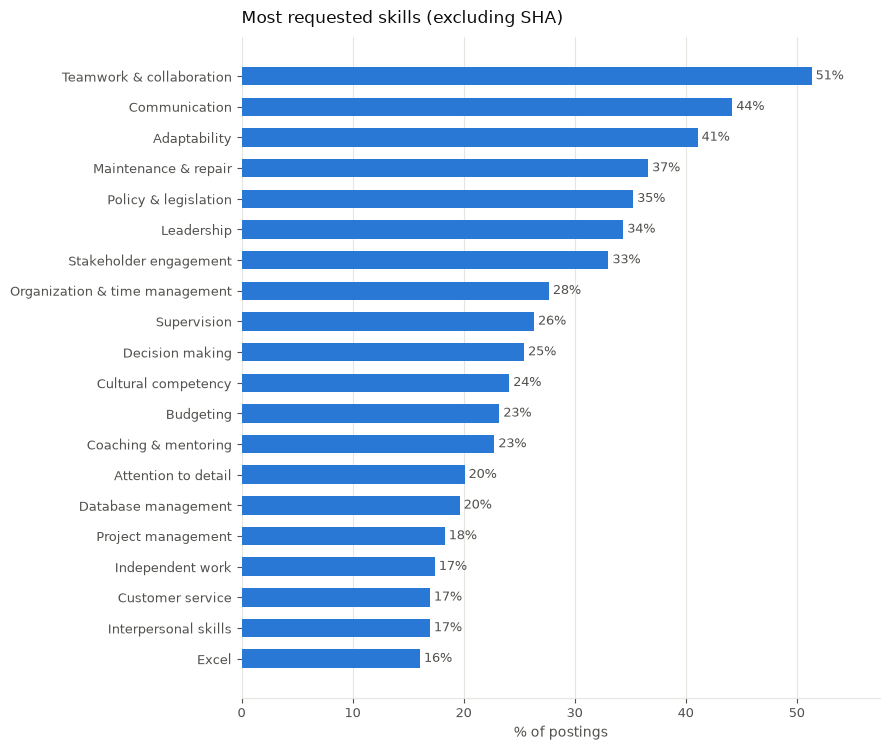

In [19]:
# Skills outside healthcare - what the crown corporations and the Government ask for
non_sha = features[~features["Source"].str.contains("Health Authority")]
barh(share_of_postings(non_sha, "Skills", 20), "Most requested skills (excluding SHA)", "% of postings", pct=True)


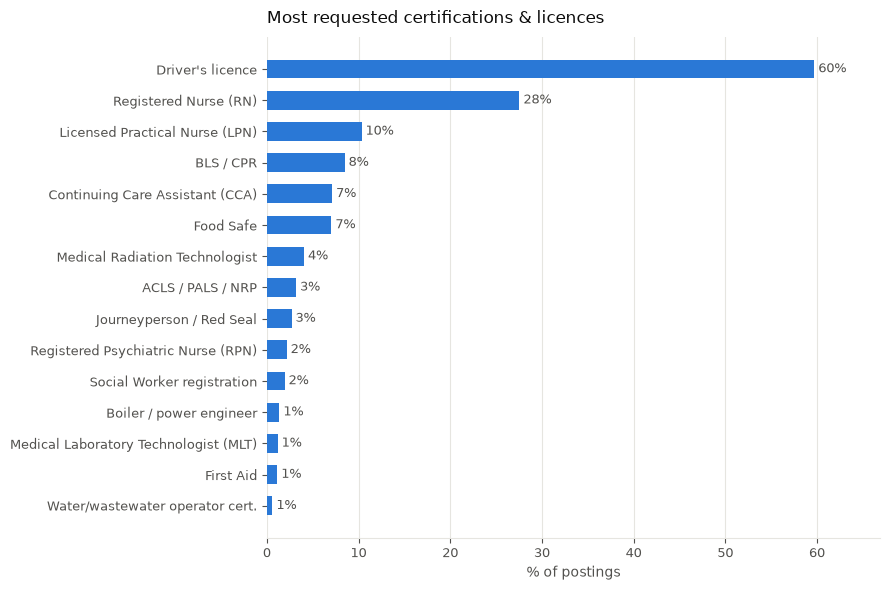

In [20]:
barh(share_of_postings(features, "Certifications", 15), "Most requested certifications & licences", "% of postings", pct=True)


In [21]:
# Required education by employer (% of postings; 'Not stated' = no education found)
order = ["High school", "Certificate / Trade", "Diploma", "Bachelor's", "Master's", "Doctorate", "Not stated"]
edu = pd.crosstab(features["Source"], features["Education_Required"].fillna("Not stated"), normalize="index") * 100
edu.reindex(columns=[c for c in order if c in edu.columns]).round(0).style.format("{:.0f}%").background_gradient(cmap="Blues", axis=None)


Education_Required,High school,Certificate / Trade,Diploma,Bachelor's,Master's,Doctorate,Not stated
Source,,,,,,,
Government of Saskatchewan,3%,7%,9%,26%,1%,0%,54%
SGI,0%,0%,75%,25%,0%,0%,0%
SaskEnergy,17%,50%,0%,33%,0%,0%,0%
SaskPower,0%,42%,0%,25%,0%,0%,33%
SaskTel,0%,29%,7%,14%,0%,0%,50%
SaskWater,4%,2%,29%,27%,0%,0%,38%
Saskatchewan Health Authority,1%,20%,21%,33%,4%,1%,20%
Saskatchewan Liquor and Gaming Authority,0%,0%,50%,0%,0%,0%,50%


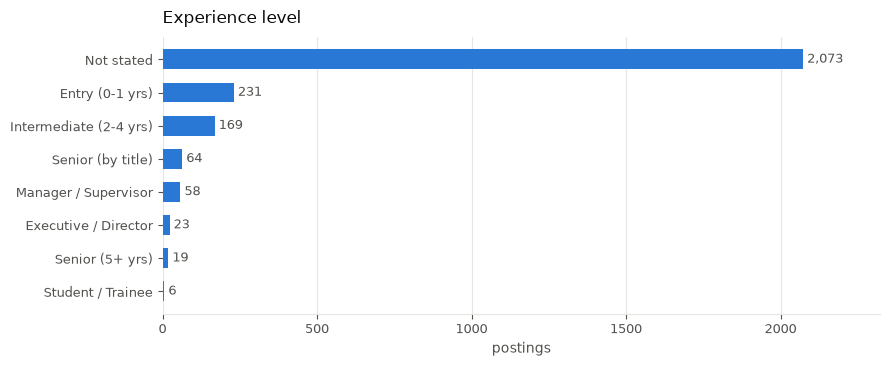

In [22]:
barh(features["Experience_Level"].value_counts(), "Experience level", "postings")


## 8. Spot-check
Compare the extracted fields with the posting text. Re-run the cell to see another random posting, and fix the taxonomy or patterns when you spot a miss.

In [23]:
row = features.sample(1).iloc[0]
print(f"{row['Source']} | {row['Job_Title']}\n")
print("QUALIFICATIONS:\n" + row["Qual_Text"][:1500] + "\n")
for col in ["Education_Required", "Education_Preferred", "Education_Field", "Experience_Years_Min",
            "Experience_Level", "Certifications", "Requirements", "Skills"]:
    print(f"{col:22} {row[col]}")


Saskatchewan Health Authority | Medical Radiation Technologist

QUALIFICATIONS:
Education: Medical Radiologic Technology Advanced diploma
Licenses: College of Medical Radiation and Imaging Professionals of Saskatchewan Canadian Association of Medical Radiation Technologists
Competencies: Basic - Computer skills Communication skills Interpersonal skills
Knowledge And Abilities: Ability to work independently

Education_Required     Diploma
Education_Preferred    nan
Education_Field        Medical Radiologic Technology Advanced
Experience_Years_Min   nan
Experience_Level       Not stated
Certifications         ["Driver's licence", 'Medical Radiation Technologist']
Requirements           []
Skills                 ['Computer skills', 'Communication', 'Interpersonal skills', 'Independent work']


## 9. Save to Mongo

In [24]:
FEATURE_FIELDS = [
    "Record_ID", "Source", "Job_Title", "Organization", "Category", "City", "Province",
    "Posting_Status", "first_seen", "last_seen", "closed_date", "Posting_Date", "Closing_Date",
    "Salary_Min", "Salary_Max", "Salary_Unit", "Employment_Type_Standardized",
    "Skills", "Skills_Software", "Skills_Business", "Skills_Healthcare", "Skills_Trades",
    "Skills_Soft", "Skills_Languages", "Skill_Count", "Certifications", "Requirements",
    "Education_Required", "Education_Rank", "Education_Preferred", "Education_Field",
    "Equivalency_Accepted", "Experience_Years_Min", "Experience_Years_Preferred",
    "Experience_Level", "Gov_Skill_Levels", "Word_Count", "Resp_Text", "Qual_Text", "Clean_Text",
]


def _plain(value):
    """pandas / numpy values -> types MongoDB can store."""
    if isinstance(value, (list, tuple)):
        return [_plain(v) for v in value]
    if value is None or value is pd.NA or value is pd.NaT:
        return None
    if hasattr(value, "item") and not isinstance(value, (str, bytes)):
        value = value.item()
    if isinstance(value, float) and np.isnan(value):
        return None
    return value


def taxonomy_version() -> str:
    """Short fingerprint of the skill/cert/requirement patterns, stored with every result."""
    import hashlib, json
    blob = json.dumps([SKILL_TAXONOMY, CERTIFICATIONS, REQUIREMENTS], sort_keys=True)
    return hashlib.sha1(blob.encode()).hexdigest()[:10]


def save_to_mongo(nlp_db, features: pd.DataFrame, source_db_name: str) -> dict:
    """Write the NLP results to their own database (e.g. sk_jobs_nlp).

    posting_features  one doc per posting (_id = Record_ID), replaced each run
    skill_taxonomy    one doc per skill / certification / requirement and its pattern
    skill_counts      one doc per run date x skill: postings and % overall and per source
    nlp_runs          one summary doc per run
    """
    now = datetime.now(timezone.utc)
    today = date.today().isoformat()
    version = taxonomy_version()

    # 1. posting_features - replace, so a re-run always reflects the current taxonomy
    ops = []
    for row in features[[c for c in FEATURE_FIELDS if c in features.columns]].to_dict("records"):
        doc = {k: _plain(v) for k, v in row.items()}
        doc.update(_id=doc["Record_ID"], extracted_at=now, extraction_date=today, taxonomy_version=version)
        ops.append(ReplaceOne({"_id": doc["_id"]}, doc, upsert=True))
    if ops:
        nlp_db["posting_features"].bulk_write(ops, ordered=False)

    # 2. skill_taxonomy - the patterns used, so results can always be traced back
    tax = [ReplaceOne({"_id": f"skill:{name}"}, {"_id": f"skill:{name}", "type": "skill", "name": name,
                                                 "category": cat, "pattern": pattern, "taxonomy_version": version},
                      upsert=True)
           for cat, skills in SKILL_TAXONOMY.items() for name, pattern in skills.items()]
    tax += [ReplaceOne({"_id": f"{kind}:{name}"}, {"_id": f"{kind}:{name}", "type": kind, "name": name,
                                                   "category": None, "pattern": pattern, "taxonomy_version": version},
                       upsert=True)
            for kind, mapping in (("certification", CERTIFICATIONS), ("requirement", REQUIREMENTS))
            for name, pattern in mapping.items()]
    nlp_db["skill_taxonomy"].bulk_write(tax, ordered=False)

    # 3. skill_counts - a dated snapshot, so skill demand can be tracked over time
    open_only = features[features["Posting_Status"] == "Open"]
    long = skills_long(open_only)
    totals = open_only.groupby("Source").size()
    counts = []
    for skill, grp in long.groupby("Skill"):
        by_source = grp.groupby("Source").size()
        counts.append({
            "run_date": today, "skill": skill, "category": SKILL_CATEGORY.get(skill),
            "open_postings": int(len(grp)),
            "share_of_open_pct": float(round(len(grp) / max(len(open_only), 1) * 100, 2)),
            "by_source": {str(src): {"postings": int(n), "share_pct": float(round(n / totals[src] * 100, 2))}
                          for src, n in by_source.items()},
            "taxonomy_version": version,
        })
    nlp_db["skill_counts"].delete_many({"run_date": today})  # same-day re-run replaces its snapshot
    if counts:
        nlp_db["skill_counts"].insert_many(counts)

    # 4. run log
    summary = {
        "run_date": today, "finished_at": now, "source_db": source_db_name,
        "postings": int(len(features)), "open": int(len(open_only)),
        "closed": int((features["Posting_Status"] == "Closed").sum()),
        "skills_found": int(long["Skill"].nunique()), "taxonomy_version": version,
    }
    nlp_db["nlp_runs"].insert_one(dict(summary))

    nlp_db["posting_features"].create_index([("Source", ASCENDING), ("Posting_Status", ASCENDING)])
    nlp_db["posting_features"].create_index([("Skills", ASCENDING)])  # multikey: find postings by skill
    nlp_db["skill_counts"].create_index([("run_date", DESCENDING), ("open_postings", DESCENDING)])
    return summary

In [25]:
summary = save_to_mongo(client[NLP_DB], features, SOURCE_DB)
summary

{'run_date': '2026-10-14',
 'finished_at': datetime.datetime(2026, 10, 14, 19, 30, 52, 404242, tzinfo=datetime.timezone.utc),
 'source_db': 'sk_jobs',
 'postings': 2643,
 'open': 2225,
 'closed': 418,
 'skills_found': 107,
 'taxonomy_version': '0921feed41'}

## Optional CSV Download

In [26]:
list_cols = ["Skills", "Skills_Software", "Skills_Business", "Skills_Healthcare", "Skills_Trades",
             "Skills_Soft", "Skills_Languages", "Certifications", "Requirements"]
export = features.drop(columns=["Other_Text", "Source_File"], errors="ignore").copy()
for col in list_cols:
    export[col] = export[col].str.join("; ")
path = f"job_postings_nlp_features_{date.today().isoformat()}.csv"

out_dir = Path(os.environ.get("NLP_OUTPUT_DIR", "outputs"))
out_dir.mkdir(parents=True, exist_ok=True)
path = out_dir / path
export.to_csv(path, index=False, encoding="utf-8-sig")
print(f"Saved {path} ({len(export):,} rows)")

Saved outputs\job_postings_nlp_features_2026-10-14.csv (2,643 rows)
